# 06. Corte de avance — Aumentos fotométricos y evaluación de FT_D1_PHOTO

**Proyecto:** diferenciación de defectos superficiales de palta Hass mediante visión artificial y aprendizaje profundo.  
**Clases:** PICADURA y RUSSET.  
**Maestría en Inteligencia Artificial — Trabajo de Investigación.**  
**Fecha de corte:** 26 de octubre de 2026.

**Propósito:** registrar el diseño y los resultados de `FT_D1_PHOTO_s42_01`, compararlos con `FT_D1_s42_03`, interpretar sus diferencias y establecer el siguiente procedimiento experimental.

> **Estado del proyecto:** entrenamiento y evaluación sobre `validation` completados. **El conjunto `test` permanece reservado.** Este documento es un reporte independiente de lectura; sus tablas y figuras se visualizan sin ejecutar código. Las celdas finales de comprobación son opcionales y **solo leen archivos**; no entrenan ni editan TIFF o pesos.


## 1. Resumen ejecutivo

- Se completó el nuevo entrenamiento **FT_D1_PHOTO** sobre las mismas particiones auditadas que FT_D1.
- El **accuracy se mantuvo en 87.40 %**: ambos modelos acertaron **111 de 127** imágenes de validación.
- El **macro-F1 aumentó de 0.7524 a 0.7876**, una mejora absoluta de **0.0352**.
- El **recall de RUSSET aumentó de 52.38 % a 71.43 %**: de **11/21 a 15/21** casos reconocidos correctamente.
- El costo de esta mejora fue un aumento de errores **PICADURA → RUSSET**, de **6 a 10**. La precisión de RUSSET disminuyó de **64.71 % a 60.00 %**.
- Las curvas de aprendizaje sugieren **sobreajuste**: mientras la pérdida de entrenamiento desciende, la pérdida de validación fluctúa y repunta. Se recuperó el checkpoint seleccionado por la menor `val_loss`.

**Conclusión preliminar:** FT_D1_PHOTO es el mejor candidato por macro-F1 **entre las corridas comparadas en validation**, pero todavía no tiene una evaluación independiente en `test` ni una estimación de variabilidad entre semillas.


## 2. Pregunta de investigación y antecedentes

**Pregunta experimental:** ¿incorporar variaciones suaves de brillo y contraste sobre ambas clases durante el fine-tuning mejora el reconocimiento de defectos frente a FT_D1, manteniendo la arquitectura, los datos y la configuración de ajuste?

El análisis exploratorio previo (reporte `05_Analisis_Preprocesamiento.ipynb`) mostró que modificar fuertemente las imágenes **solo durante la inferencia** —brillo ×2.0 y contraste ×1.25— no mejoraba el macro-F1: pasó de **0.7524** a **0.7433**. Aunque el recall de RUSSET subió de **0.5238** a **0.5714**, se corrigieron cuatro errores y se introdujeron seis nuevos.

FT_D1_PHOTO responde a otra hipótesis: **enseñar al modelo variaciones moderadas durante el entrenamiento**, en lugar de alterar exclusivamente las imágenes de evaluación. No debe confundirse una prueba con la otra.


## 3. Dataset, integridad y unidades de análisis

El dataset auditado consta de **829 archivos TIFF**. Cada TIFF contiene una palta, con **tres franjas horizontales** correspondientes a cámaras distintas y múltiples vistas por rotación. El archivo completo se usa como unidad de clasificación; no se dividen sus franjas entre conjuntos.

| Partición | PICADURA original | RUSSET original | Total original | Elegibles tras auditoría |
|:---|---:|---:|---:|---:|
| Train | 497 | 77 | 574 | **572** |
| Validation | 107 | 21 | 128 | **127** |
| Test | 106 | 21 | 127 | **126** |
| **Total** | **710** | **119** | **829** | **825** |

Se conservaron **cuatro exclusiones lógicas** previamente documentadas, sin borrar archivos originales. El notebook del experimento vuelve a comprobar las firmas y SHA-256 antes de entrenar, y valida la reproducción del plan D1.

El entrenamiento parte de **572 TIFF elegibles** (495 PICADURA y 77 RUSSET) más **77 copias aumentadas de RUSSET**, equivalentes a **649 muestras por época**. Estas copias se generan en memoria: **no son archivos TIFF adicionales**.

**Límite de auditoría:** los hashes y las exclusiones de duplicados exactos no sustituyen una comprobación de independencia por fruto, lote o sesión; esta trazabilidad sigue siendo un aspecto a verificar si se dispone de metadatos adicionales.


## 4. Diseño experimental controlado

| Parámetro | FT_D1 (`FT_D1_s42_03`) | FT_D1_PHOTO (`FT_D1_PHOTO_s42_01`) |
|:---|:---|:---|
| Modelo base | ResNet50 preentrenada con ImageNet | **Igual** |
| Checkpoint inicial | Cabeza entrenada de `D1_s42_03` | **El mismo** |
| Entrada | 256 × 512 píxeles (alto × ancho) | **Igual** |
| Datos de train | 572 originales elegibles + 77 copias RUSSET | **Igual** |
| Aumentos D1 en 77 copias | Brillo 0.92–1.08; contraste 0.90–1.10 | **Conservados** |
| **Aumento adicional** | No | **Brillo y contraste 0.95–1.05 para ambas clases, renovado por visita** |
| Capas entrenables | Bloque `conv5` y cabeza | **Igual** |
| BatchNormalization | Congelada | **Igual** |
| Optimizador | Adam | **Igual** |
| Learning rate | `1e-5` | **Igual** |
| Lote / épocas máximas / semilla | 1 / 8 / 42 | **Igual** |
| Selección de checkpoint | Menor `val_loss` | **Igual** |
| Validation | 127 TIFF sin aumento adicional | **Los mismos 127 TIFF** |
| Test | Reservado | **Reservado** |

**Implementación del tratamiento:** el incremento fotométrico solo actúa sobre los píxeles de la imagen, empleando la máscara devuelta por `ajustar_tamano` para mantener constante el relleno. No cambia el orden de cámaras, la posición de las vistas, las etiquetas ni las imágenes originales. Durante cada visita se generan factores reproducibles a partir de la semilla y el índice de la muestra.

**Callbacks utilizados:** `ModelCheckpoint` y `EarlyStopping` supervisan `val_loss`; también se usan `ReduceLROnPlateau`, `CSVLogger` y `TerminateOnNaN`. La evaluación se ejecuta tras cargar el checkpoint conservado como el mejor, no necesariamente el de la última época.


## 5. Comparación cuantitativa de modelos

Las cifras corresponden exclusivamente a **validation (127 TIFF)**.

| Métrica | FT_D1 | FT_D1_PHOTO | Diferencia PHOTO − FT_D1 |
|:---|---:|---:|---:|
| **Accuracy** | 0.8740 | **0.8740** | 0.0000 |
| **Macro-F1** | 0.7524 | **0.7876** | **+0.0352** |
| Recall PICADURA | 0.9434 | 0.9057 | −0.0377 |
| Recall RUSSET | 0.5238 | **0.7143** | **+0.1905** |
| Precision RUSSET | **0.6471** | 0.6000 | −0.0471 |
| F1 RUSSET | 0.5789 | **0.6522** | +0.0733 |
| Aciertos RUSSET | 11 de 21 | **15 de 21** | **+4** |
| Aciertos globales | 111 de 127 | 111 de 127 | 0 |

La métrica prioritaria del trabajo es **macro-F1**, que asigna el mismo peso a las dos clases y resulta más informativa que accuracy cuando existe desbalance. Aquí la mejora de macro-F1 **no** equivale a más aciertos globales, sino a una **distribución más equilibrada de aciertos entre clases**.

*Los valores mostrados están redondeados a cuatro decimales; las diferencias se interpretan con esa precisión.*


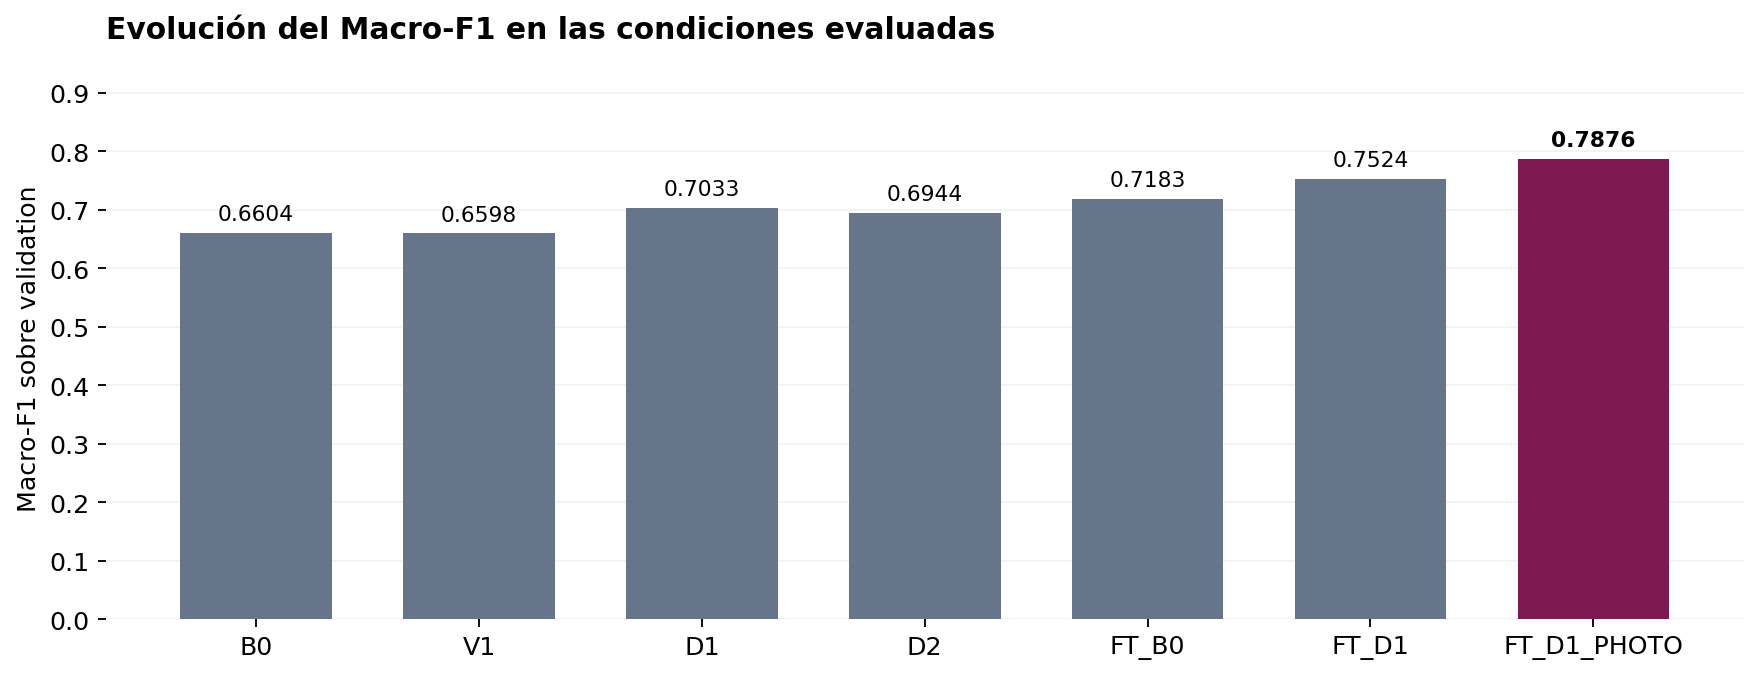

*Macro-F1 para los siete experimentos descritos en los cortes de investigación 03, 04 y 06. Las primeras seis corridas se documentaron antes de FT_D1_PHOTO.*

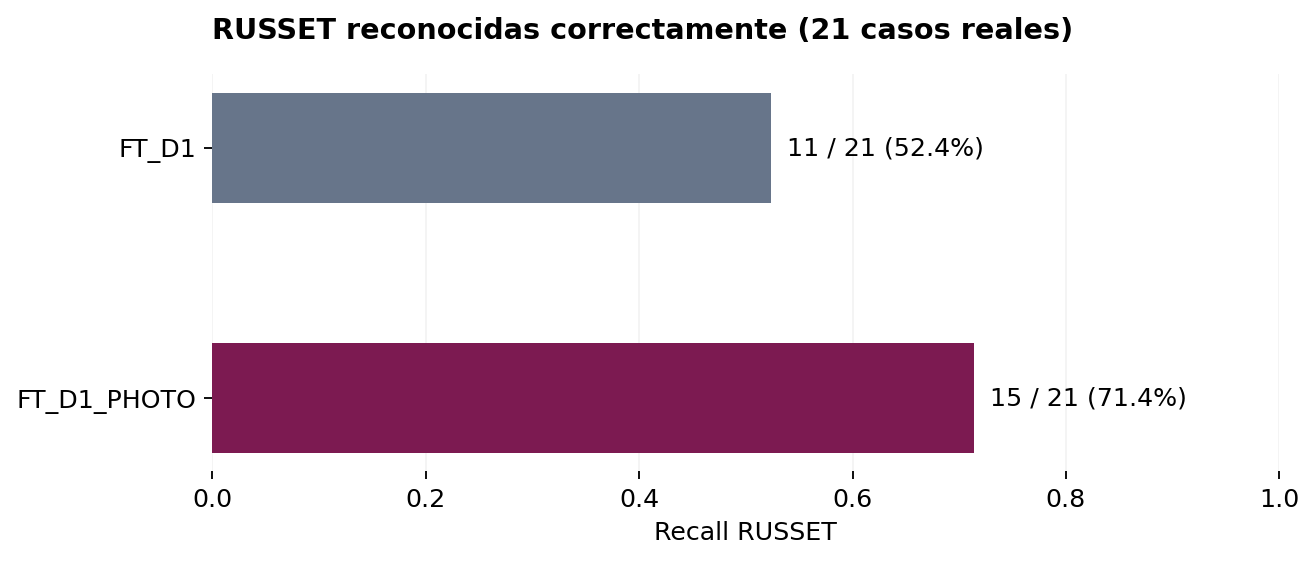

*El recall de RUSSET pasó de 11/21 a 15/21 (cuatro imágenes adicionales correctamente clasificadas).*

## 6. Matrices de confusión e intercambio entre errores

Filas: **clase real**. Columnas: **clase predicha**. La diagonal muestra aciertos.

| Clase real / Predicción | FT_D1: PICADURA | FT_D1: RUSSET | FT_D1_PHOTO: PICADURA | FT_D1_PHOTO: RUSSET |
|:---|---:|---:|---:|---:|
| PICADURA (106) | **100** | 6 | **96** | 10 |
| RUSSET (21) | 10 | **11** | 6 | **15** |

**Interpretación:**

- En FT_D1_PHOTO, **4 RUSSET adicionales** quedan bien clasificadas respecto al total de aciertos por clase de FT_D1.
- Simultáneamente, **4 PICADURA menos** quedan correctamente clasificadas.
- Por eso los errores totales se mantienen en **16**, aunque el macro-F1 mejora.
- Este cuadro no permite identificar todavía **qué archivos concretos** cambiaron de predicción. La comparación emparejada se realiza con los CSV guardados (celda opcional al final).


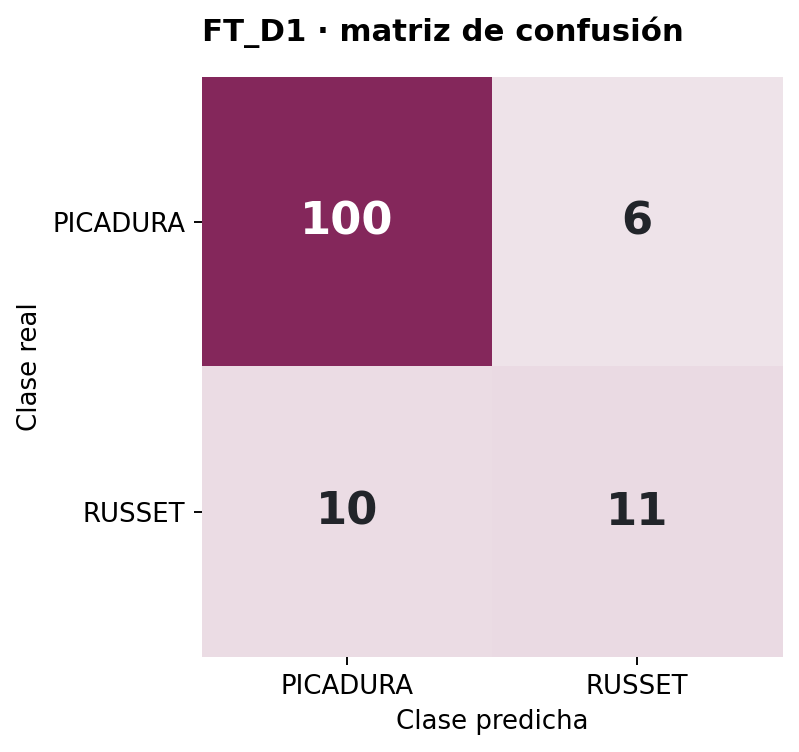

*Matriz de confusión de FT_D1 calculada a partir de los recuentos guardados del corte anterior.*

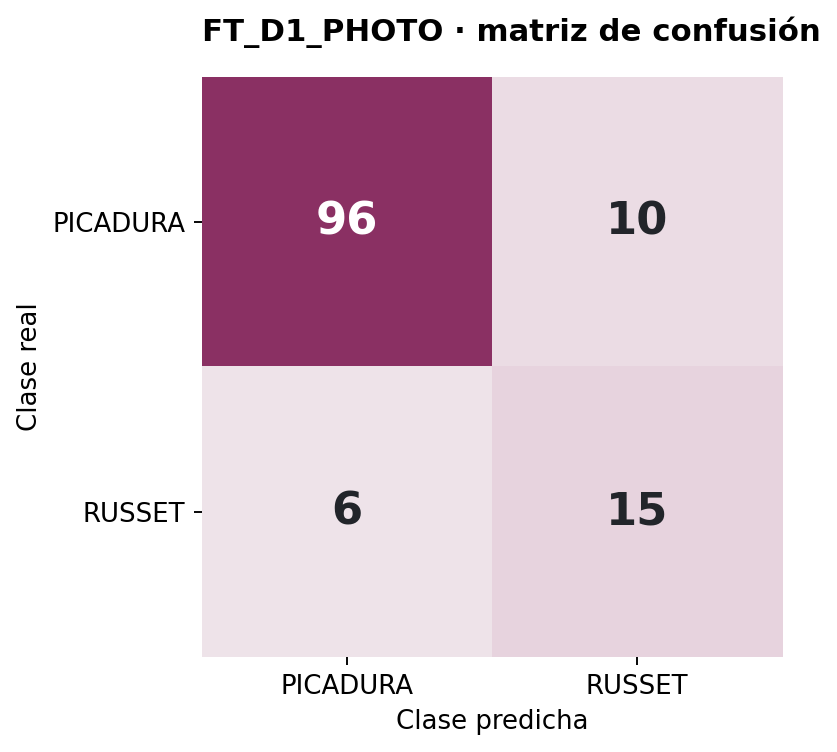

*Matriz de confusión de FT_D1_PHOTO basada en los 127 resultados de validation mostrados al finalizar la corrida.*

## 7. Evidencia de la corrida completa

La ejecución y la comparación posterior mostraron ambos estados como **`completo`**, además de las métricas coincidentes. La captura original se conserva aquí como evidencia de la salida en VS Code/Jupyter.


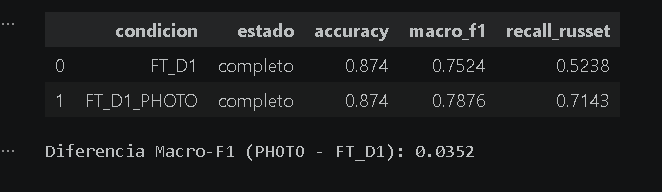

*Salida registrada de la sección 10 del notebook de entrenamiento: igualdad de accuracy y diferencia de macro-F1 = 0.0352.*

## 8. Comportamiento del entrenamiento y posible sobreajuste

Las gráficas obtenidas muestran una reducción importante de la pérdida de entrenamiento y una exactitud de train que se aproxima al 99 % hacia el final de las ocho épocas. En contraste, la pérdida de validación presenta oscilaciones y subidas después de un mínimo intermedio, mientras que su accuracy permanece por debajo de la de entrenamiento.

El patrón es **compatible con sobreajuste**, pero por sí solo no identifica la causa. Puede influir el número reducido de muestras, la variación de iluminación entre adquisiciones o las semejanzas visuales entre las clases. Son hipótesis, no causas demostradas.

La rutina guarda el checkpoint que minimiza `val_loss`. La **época exacta** y el mínimo numérico deben confirmarse leyendo `estado.json` e `historial.csv`; no se infieren de una captura redondeada. Hay una celda opcional de comprobación al final.


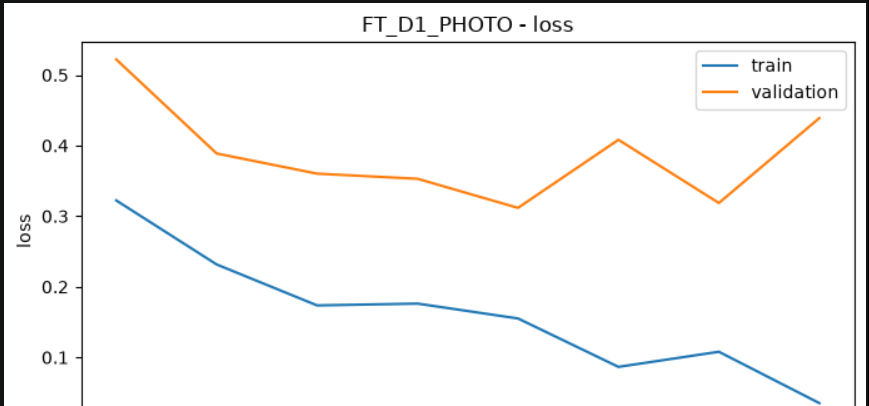

*Captura real de las curvas de pérdida (train y validation) de FT_D1_PHOTO.*

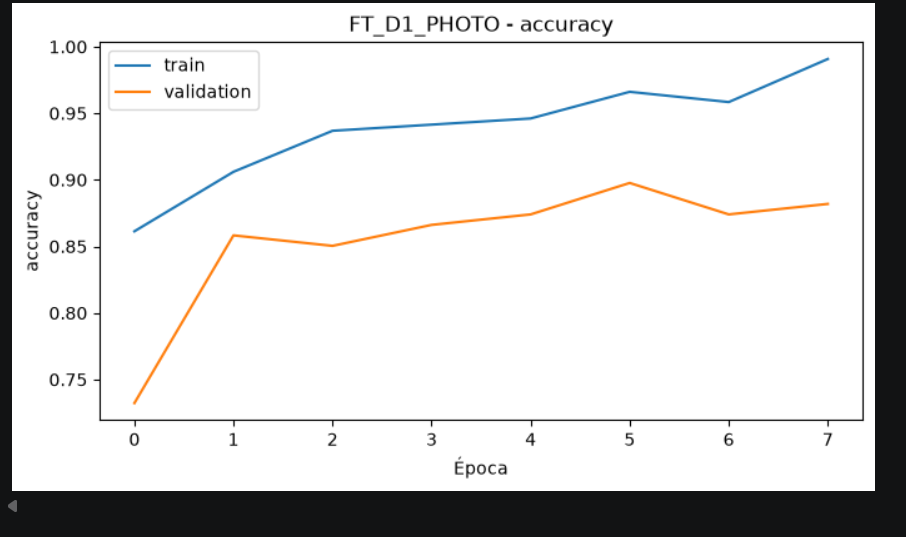

*Captura real de las curvas de accuracy de FT_D1_PHOTO.*

## 9. Interpretación técnica

**Qué respalda la evidencia:** para la partición validation y la semilla utilizada, añadir variaciones fotométricas suaves a **ambas** clases durante el fine-tuning produjo un mejor macro-F1 y mayor recall de RUSSET, conservando el accuracy global. El nuevo modelo es un candidato de selección más conveniente **si macro-F1 es el criterio principal**.

**Qué no respalda todavía:** no demuestra que la mejora se mantenga ante nuevas campañas, lotes, cámaras o imágenes de otras condiciones. Tampoco permite asegurar que la iluminación sea la causa original de los errores, ni que el aumento observado sea estadísticamente estable.

**Contraste con la prueba previa:** cambiar mucho el brillo de las imágenes solo en inferencia no mejoró el macro-F1; en cambio, introducir variaciones suaves durante el entrenamiento sí lo mejoró en validation. Este contraste es una observación útil para la discusión metodológica, pero no reemplaza el control de generalización.


## 10. Limitaciones y riesgos metodológicos

1. **Pocas RUSSET en validation:** 21 casos. Un acierto RUSSET representa **4.76 puntos porcentuales** de recall. Variaciones pequeñas en recuentos cambian notablemente la métrica.
2. **Una única corrida con semilla 42:** no se ha estimado dispersión entre entrenamientos independientes ni intervalos de incertidumbre.
3. **Reutilización de validation:** se han comparado varias variantes en el mismo conjunto; seleccionar repetidamente por sus resultados puede generar una estimación optimista de rendimiento.
4. **Independencia por origen:** la auditoría de duplicados idénticos no demuestra que no existan paltas relacionadas por lote, sesión o condición de captura entre particiones.
5. **Compromiso precisión/recall:** el modelo detecta más RUSSET, pero también etiqueta como RUSSET a más PICADURA. Un despliegue real exige definir el costo de cada tipo de error junto con el área de calidad.
6. **Sin evaluación de test:** no es correcto presentar 0.7876 como desempeño final en datos completamente reservados.

Hasta completar estos puntos, la formulación adecuada es **"mejora observada en validation"**, no "mejora definitiva del sistema".


## 11. Conclusiones del corte

**Conclusión 1.** El ajuste fotométrico durante train permitió pasar de **11 a 15 RUSSET reconocidas** entre las 21 observadas en validation, elevando el recall de **0.5238 a 0.7143**.

**Conclusión 2.** La principal mejora global fue en **macro-F1 (0.7524 → 0.7876)**, no en accuracy, que se mantuvo en **0.8740**. Se trata de una redistribución de errores hacia la clase PICADURA.

**Conclusión 3.** Los aumentos se aplicaron sin modificar los TIFF, preservando el conjunto de entrenamiento auditado y las unidades multivista de cada palta.

**Conclusión 4.** La brecha entre las curvas de train y validation requiere considerar sobreajuste y justificar la selección del mejor checkpoint, antes de presentar el modelo como listo para despliegue.

**Conclusión 5.** FT_D1_PHOTO se selecciona **provisionalmente** como candidato de mayor macro-F1 en validation. `test` sigue intacto para la comparación final de generalización, después de fijar el protocolo.


## 12. Plan de trabajo: qué hacer a continuación

| Orden | Acción | Resultado esperado | ¿Reentrena? |
|:---:|:---|:---|:---:|
| **1** | **Cerrar la corrida:** dejar `EJECUTAR_EXPERIMENTO = False`, guardar el notebook de entrenamiento y conservar la carpeta `FT_D1_PHOTO_s42_01` | Checkpoint y métricas protegidos frente a ejecuciones accidentales | No |
| **2** | **Examinar las predicciones emparejadas:** leer los dos archivos `predicciones_validation.csv`; identificar TIFF corregidos, nuevos errores y casos persistentes | Tabla de cambios por archivo y clase | No |
| **3** | **Revisar los errores RUSSET y PICADURA** visualmente, sin separar las tres franjas del TIFF; registrar iluminación, textura y posibles etiquetas ambiguas como observaciones | Análisis de errores documentado, sin atribuir causalidad prematura | No |
| **4** | **Confirmar checkpoint e historial** a partir de `estado.json` e `historial.csv`; documentar la época elegida por `val_loss` | Registro exacto de selección de pesos y curvas | No |
| **5** | **Congelar criterios de elección:** FT_D1_PHOTO como candidato principal por macro-F1; definir cualquier repetición de semillas antes de consultar `test` | Protocolo cerrado, evitando nuevas decisiones sobre el test | Solo si se decide una réplica |
| **6** | **Evaluación final única sobre `test` reservado (126 TIFF)**, tras cerrar la selección y verificar las particiones | Accuracy, Macro-F1, recall, precisión y matriz de confusión de test | No: solo inferencia |
| **7** | Actualizar el informe de tesis con métodos, matrices, riesgos y alcance de las conclusiones | Resultados reproducibles y discusión metodológica | No |

**Próximo paso inmediato recomendado:** ejecutar **solo las celdas opcionales de lectura** de las secciones 14.1 y 14.2 de este reporte para identificar exactamente cuáles imágenes cambiaron entre FT_D1 y FT_D1_PHOTO. No conviene entrenar otra variante ni abrir `test` todavía.


## 13. Rutas y archivos que deben conservarse

| Tipo | Ruta dentro de `PROYECTO_TI_2` | Uso |
|:---|:---|:---|
| Notebook principal | `6. entrenamiento/resnet50.ipynb` | Historial de entrenamiento general |
| Notebook del nuevo experimento | `6. entrenamiento/02_Experimento_Aumentos_Fotometricos.ipynb` | Protocolo y entrenamiento FT_D1_PHOTO |
| Modelo de partida D1 | `7. resultados/entrenamiento/D1_s42_03/` | `mejor_cabeza.weights.h5`, plan de copias y configuración |
| Referencia anterior | `7. resultados/entrenamiento/FT_D1_s42_03/` | Métricas, CSV, checkpoint previo |
| **Nueva corrida** | **`7. resultados/entrenamiento/FT_D1_PHOTO_s42_01/`** | Nuevo checkpoint, predicciones, matrices e historial |
| **Este reporte** | **`1. fuentes/06_Reporte_FT_D1_PHOTO.ipynb`** | Documento independiente de análisis |

Archivos relevantes bajo la carpeta de cada modelo: `configuracion.json`, `metricas_validation.json`, `predicciones_validation.csv`, `matriz_confusion_validation.csv` y `mejor_finetune.weights.h5`. En FT_D1_PHOTO también se generan `estado.json`, `historial.csv`, `curva_loss.png` y `curva_accuracy.png`.

**Conservación:** no borrar ni sobrescribir `FT_D1_s42_03`, `FT_D1_PHOTO_s42_01` ni los TIFF. El nuevo notebook de análisis no necesita acceder a esos archivos para mostrar las conclusiones y gráficas incluidas.


---

## 14. Comprobaciones opcionales (solo lectura)

Estas dos celdas no entrenan, no crean modelos y no alteran los resultados guardados. **No necesitas ejecutarlas para leer el informe.** Si deseas continuar con el análisis de errores, ejecútalas en orden desde VS Code con WSL.

### 14.1. Verificar que las dos métricas guardadas sean comparables


In [ ]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

RAIZ_REPORTE = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "7. resultados" / "entrenamiento").is_dir()
     and (p / "utilidades_imagenes.py").is_file()),
    None
)
if RAIZ_REPORTE is None:
    raise FileNotFoundError("Abrir desde el proyecto PROYECTO_TI_2 en VS Code / WSL.")

CARPETA_RESULTADOS = RAIZ_REPORTE / "7. resultados" / "entrenamiento"
CORRIDAS = {
    "FT_D1": CARPETA_RESULTADOS / "FT_D1_s42_03",
    "FT_D1_PHOTO": CARPETA_RESULTADOS / "FT_D1_PHOTO_s42_01",
}

filas = []
for nombre, ruta in CORRIDAS.items():
    archivo = ruta / "metricas_validation.json"
    if not archivo.is_file():
        raise FileNotFoundError(f"Archivo de métricas no encontrado: {archivo}")
    datos = json.loads(archivo.read_text(encoding="utf-8"))
    if datos.get("estado") != "completo" or datos.get("particion") != "validation":
        raise RuntimeError(f"La corrida {nombre} no figura completa sobre validation")
    filas.append({
        "condicion": nombre,
        "accuracy": float(datos["accuracy"]),
        "macro_f1": float(datos["macro_f1"]),
        "recall_russet": float(datos["recall_russet"]),
    })

METRICAS_REPORTE = pd.DataFrame(filas).set_index("condicion")
display(METRICAS_REPORTE.round(4))
print("Diferencia Macro-F1:", round(
    METRICAS_REPORTE.loc["FT_D1_PHOTO", "macro_f1"]
    - METRICAS_REPORTE.loc["FT_D1", "macro_f1"], 4
))


### 14.2. Identificar archivos corregidos y nuevos errores

Esta celda compara **imagen por imagen** las dos predicciones, comprueba que ambas corridas contienen los mismos archivos y muestra el resultado por clase. No modifica ningún CSV; solo lee y presenta tablas en pantalla.


In [ ]:
import numpy as np

columnas = ["archivo", "clase", "prediccion"]
previa = pd.read_csv(CORRIDAS["FT_D1"] / "predicciones_validation.csv")
actual = pd.read_csv(CORRIDAS["FT_D1_PHOTO"] / "predicciones_validation.csv")

faltan = [c for c in columnas if c not in previa.columns or c not in actual.columns]
if faltan:
    raise ValueError(f"Faltan columnas en los CSV: {faltan}")
if previa["archivo"].duplicated().any() or actual["archivo"].duplicated().any():
    raise ValueError("Los CSV contienen archivos duplicados; revisar antes de comparar")

cambios_reporte = previa[columnas].rename(columns={
    "clase": "real_previa", "prediccion": "prediccion_FT_D1"
}).merge(
    actual[columnas].rename(columns={
        "clase": "real_actual", "prediccion": "prediccion_FT_D1_PHOTO"
    }),
    on="archivo", how="outer", validate="one_to_one", indicator=True
)
if (len(cambios_reporte) != 127 or
        not cambios_reporte["_merge"].eq("both").all() or
        not cambios_reporte["real_previa"].eq(cambios_reporte["real_actual"]).all()):
    raise RuntimeError("Las corridas no contienen exactamente los mismos casos de validación")

cambios_reporte["clase_real"] = cambios_reporte["real_previa"]
antes_ok = cambios_reporte["prediccion_FT_D1"].eq(cambios_reporte["clase_real"])
despues_ok = cambios_reporte["prediccion_FT_D1_PHOTO"].eq(cambios_reporte["clase_real"])
cambios_reporte["situacion"] = np.select(
    [(~antes_ok) & despues_ok, antes_ok & (~despues_ok),
     (~antes_ok) & (~despues_ok)],
    ["error_corregido", "nuevo_error", "error_persistente"],
    default="acierto_mantenido"
)

print("Resumen por clase (cantidad de TIFF):")
display(pd.crosstab(
    cambios_reporte["clase_real"], cambios_reporte["situacion"]
))
print("Archivos cuya predicción cambió:")
display(cambios_reporte.loc[
    cambios_reporte["prediccion_FT_D1"]
    != cambios_reporte["prediccion_FT_D1_PHOTO"],
    ["archivo", "clase_real", "prediccion_FT_D1",
     "prediccion_FT_D1_PHOTO", "situacion"]
].sort_values(["clase_real", "situacion", "archivo"]).reset_index(drop=True))


### 14.3. Época elegida y verificación del checkpoint (opcional)

La siguiente celda **solo lee** el historial y el estado de la corrida nueva. Evita deducir la mejor época desde una curva representada con resolución limitada.


In [ ]:
carpeta_photo = CORRIDAS["FT_D1_PHOTO"]
archivo_historial = carpeta_photo / "historial.csv"
archivo_estado = carpeta_photo / "estado.json"
archivo_pesos = carpeta_photo / "mejor_finetune.weights.h5"

for archivo in (archivo_historial, archivo_estado, archivo_pesos):
    if not archivo.is_file():
        raise FileNotFoundError(str(archivo))

historial_photo = pd.read_csv(archivo_historial)
estado_photo = json.loads(archivo_estado.read_text(encoding="utf-8"))
if "val_loss" not in historial_photo.columns or historial_photo.empty:
    raise RuntimeError("Falta val_loss o el historial está vacío")

mejor_indice = historial_photo["val_loss"].astype(float).idxmin()
print("Estado:", estado_photo.get("estado"))
print("Épocas registradas:", len(historial_photo))
print("Mejor época (val_loss):", int(mejor_indice) + 1)
print("Menor val_loss:", round(float(historial_photo.loc[mejor_indice, "val_loss"]), 6))
print("Checkpoint disponible:", archivo_pesos.is_file())


---

### Cierre del reporte

**Decisión provisional:** conservar `FT_D1_PHOTO_s42_01` como candidato principal por macro-F1 en `validation`; preservar `FT_D1_s42_03` como referencia. El **siguiente trabajo** es comparar las predicciones caso a caso y revisar errores con evidencia visual. Solo después de cerrar el protocolo corresponde realizar una evaluación final **una única vez** sobre `test`, sin utilizar ese resultado para ajustar el modelo.

**Archivos de referencia:** `03_Corte_Avance_ResNet50_B0_V1_D1_D2.ipynb`, `04_Analisis_Errores_ResNet50.ipynb`, `05_Analisis_Preprocesamiento.ipynb`, `6. entrenamiento/02_Experimento_Aumentos_Fotometricos.ipynb` y las carpetas de resultados originales descritas en este informe.
